#A



29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
訓練資料 X_train 形狀: (60000, 28, 28)
訓練標籤 y_train 形狀: (60000,)
測試資料 X_test 形狀: (10000, 28, 28)
測試標籤 y_test 形狀: (10000,)


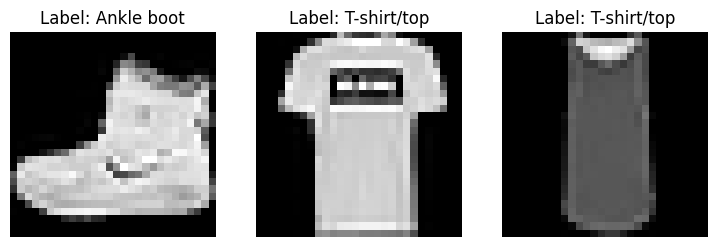

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix
import seaborn as sns

# 1. 載入 Fashion-MNIST 資料
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# 2. 定義 Fashion-MNIST 的 10 個類別名稱 (對應課本 p.2-46)
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# 3. 呈現訓練與測試資料的形狀
print("訓練資料 X_train 形狀:", X_train.shape)
print("訓練標籤 y_train 形狀:", y_train.shape)
print("測試資料 X_test 形狀:", X_test.shape)
print("測試標籤 y_test 形狀:", y_test.shape)

# 4. 顯示三張訓練資料及其真實標籤名稱[cite: 4]
plt.figure(figsize=(9, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {class_names[y_train[i]]}")
    plt.axis('off')
plt.show()

# 5. 資料正規化與展平 (將 28x28 影像轉為 784 維向量)
X_train = X_train.reshape(-1, 28 * 28).astype('float32') / 255.0
X_test = X_test.reshape(-1, 28 * 28).astype('float32') / 255.0

# 6. One-hot Encoding 標籤
y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)


#B

In [4]:
model = Sequential([
    # 第一隱藏層：512個神經元，輸入特徵為 784
    Dense(512, activation='relu', input_shape=(784,)),
    Dropout(0.3),

    # 第二隱藏層：256個神經元
    Dense(256, activation='relu'),
    Dropout(0.3),

    # 輸出層：10個神經元 (對應 10 類)，使用 softmax 激發函數
    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

#C

In [5]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 訓練模型 (切出 20% 作為 validation_data)[cite: 4]
history = model.fit(
    X_train, y_train_onehot,
    batch_size=128,
    epochs=25,
    validation_split=0.2,
    verbose=1
)

Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.7917 - loss: 0.5836 - val_accuracy: 0.8257 - val_loss: 0.4468
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8482 - loss: 0.4180 - val_accuracy: 0.8565 - val_loss: 0.3863
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8593 - loss: 0.3830 - val_accuracy: 0.8735 - val_loss: 0.3472
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.8671 - loss: 0.3615 - val_accuracy: 0.8742 - val_loss: 0.3417
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8746 - loss: 0.3454 - val_accuracy: 0.8774 - val_loss: 0.3379
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.8803 - loss: 0.3297 - val_accuracy: 0.8748 - val_loss: 0.3376
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8832 - loss: 0.3159 - val_accuracy: 0.8824 - val_loss: 0.3235
Epoch 8/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.8853 - loss: 0.3070 - val_acc

#D

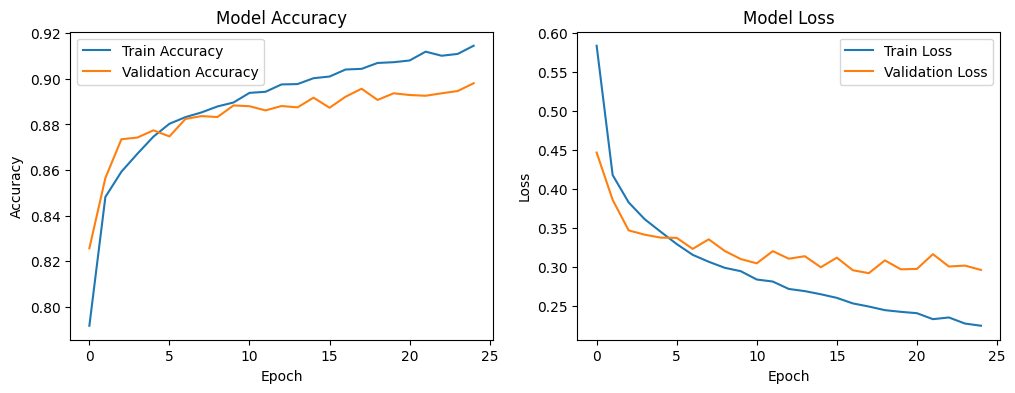

In [6]:
plt.figure(figsize=(12, 4))

# 準確率變化圖
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# 損失誤差變化圖
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

#E

測試資料集的準確率 (Accuracy): 88.97%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


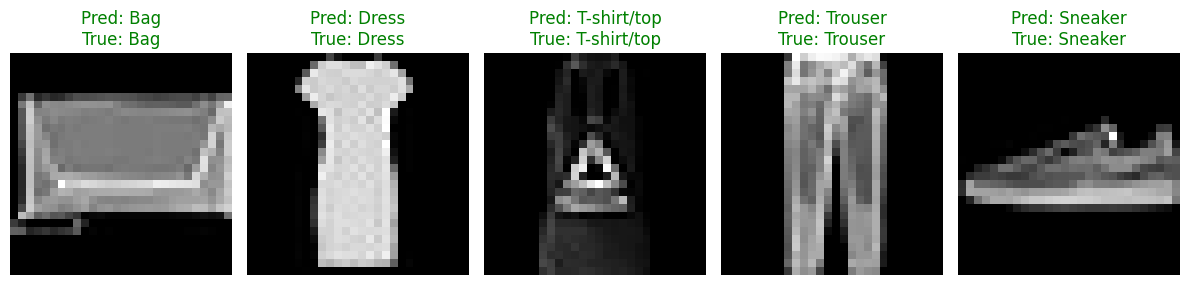

In [7]:
# e. 評估模型準確率[cite: 4]
test_loss, test_acc = model.evaluate(X_test, y_test_onehot, verbose=0)
print(f"測試資料集的準確率 (Accuracy): {test_acc * 100:.2f}%")

# f. 進行預測[cite: 4]
predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)

# 隨機挑選 5 張測試圖片檢查預測結果
plt.figure(figsize=(12, 5))
for i in range(5):
    idx = np.random.randint(0, len(X_test))
    plt.subplot(1, 5, i + 1)
    # 將一維特徵還原回 28x28 顯示圖片
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    pred_label = class_names[predicted_classes[idx]]
    true_label = class_names[y_test[idx]]

    color = 'green' if predicted_classes[idx] == y_test[idx] else 'red'
    plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

#G

In [ ]:
cm = confusion_matrix(y_test, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

#H

In [ ]:
# 儲存模型為 h5 格式
model.save("fashion_mnist_dnn_model.h5")
print("模型已成功儲存為 fashion_mnist_dnn_model.h5")